# CSE422 Lab Project






## 1. Import Libraries & Config

In [14]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_curve, auc, ConfusionMatrixDisplay
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning

# Silence noisy warnings for a clean notebook
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Notebook-level config
DATA_PATH = "Depression Data.csv"  # ensure this file is in the working directory
USE_DEPRESSION_VALUE_AS_FEATURE = False   # keep False to avoid leakage
RANDOM_STATE = 42

plt.style.use("default")
sns.set(font_scale=0.95)


## 2. Load Dataset & Initial Exploration (No Head Preview)

In [2]:
df = pd.read_csv(DATA_PATH)

# Clean minimal: convert literal 'nan' strings; strip col names
df = df.replace('nan', np.nan)
df.columns = [c.strip() for c in df.columns]

print("Shape:", df.shape)
print("Columns:", list(df.columns))

# Compact dtypes to avoid long questionnaire spam
DTYPE_KEEP_COLS = [
    '1. Age','2. Gender','5. Academic Year','6. Current CGPA',
    '7. Did you receive a waiver or scholarship at your university?',
    'Anxiety Value','Stress Value','Depression Value','Depression Label'
]
dtype_cols = [c for c in DTYPE_KEEP_COLS if c in df.columns]
print("\nDtypes (compact):\n", df[dtype_cols].dtypes)

# FULL missing counts (all columns) — keep exactly like requested
print("\nMissing counts:\n", df.isna().sum().sort_values(ascending=False))


Shape: (1977, 37)
Columns: ['1. Age', '2. Gender', '5. Academic Year', '6. Current CGPA', '7. Did you receive a waiver or scholarship at your university?', '1. In a semester, how often you felt nervous, anxious or on edge due to academic pressure?', '2. In a semester, how often have you been unable to stop worrying about your academic affairs?', '3. In a semester, how often have you had trouble relaxing due to academic pressure?', '4. In a semester, how often have you been easily annoyed or irritated because of academic pressure?', '5. In a semester, how often have you worried too much about academic affairs?', '6. In a semester, how often have you been so restless due to academic pressure that it is hard to sit still?', '7. In a semester, how often have you felt afraid, as if something awful might happen?', 'Anxiety Value', 'Anxiety Label', '1. In a semester, how often have you felt upset due to something that happened in your academic affairs?', '2. In a semester, how often you felt 

## 3. Exploratory Data Analysis (EDA): Correlation Heatmap

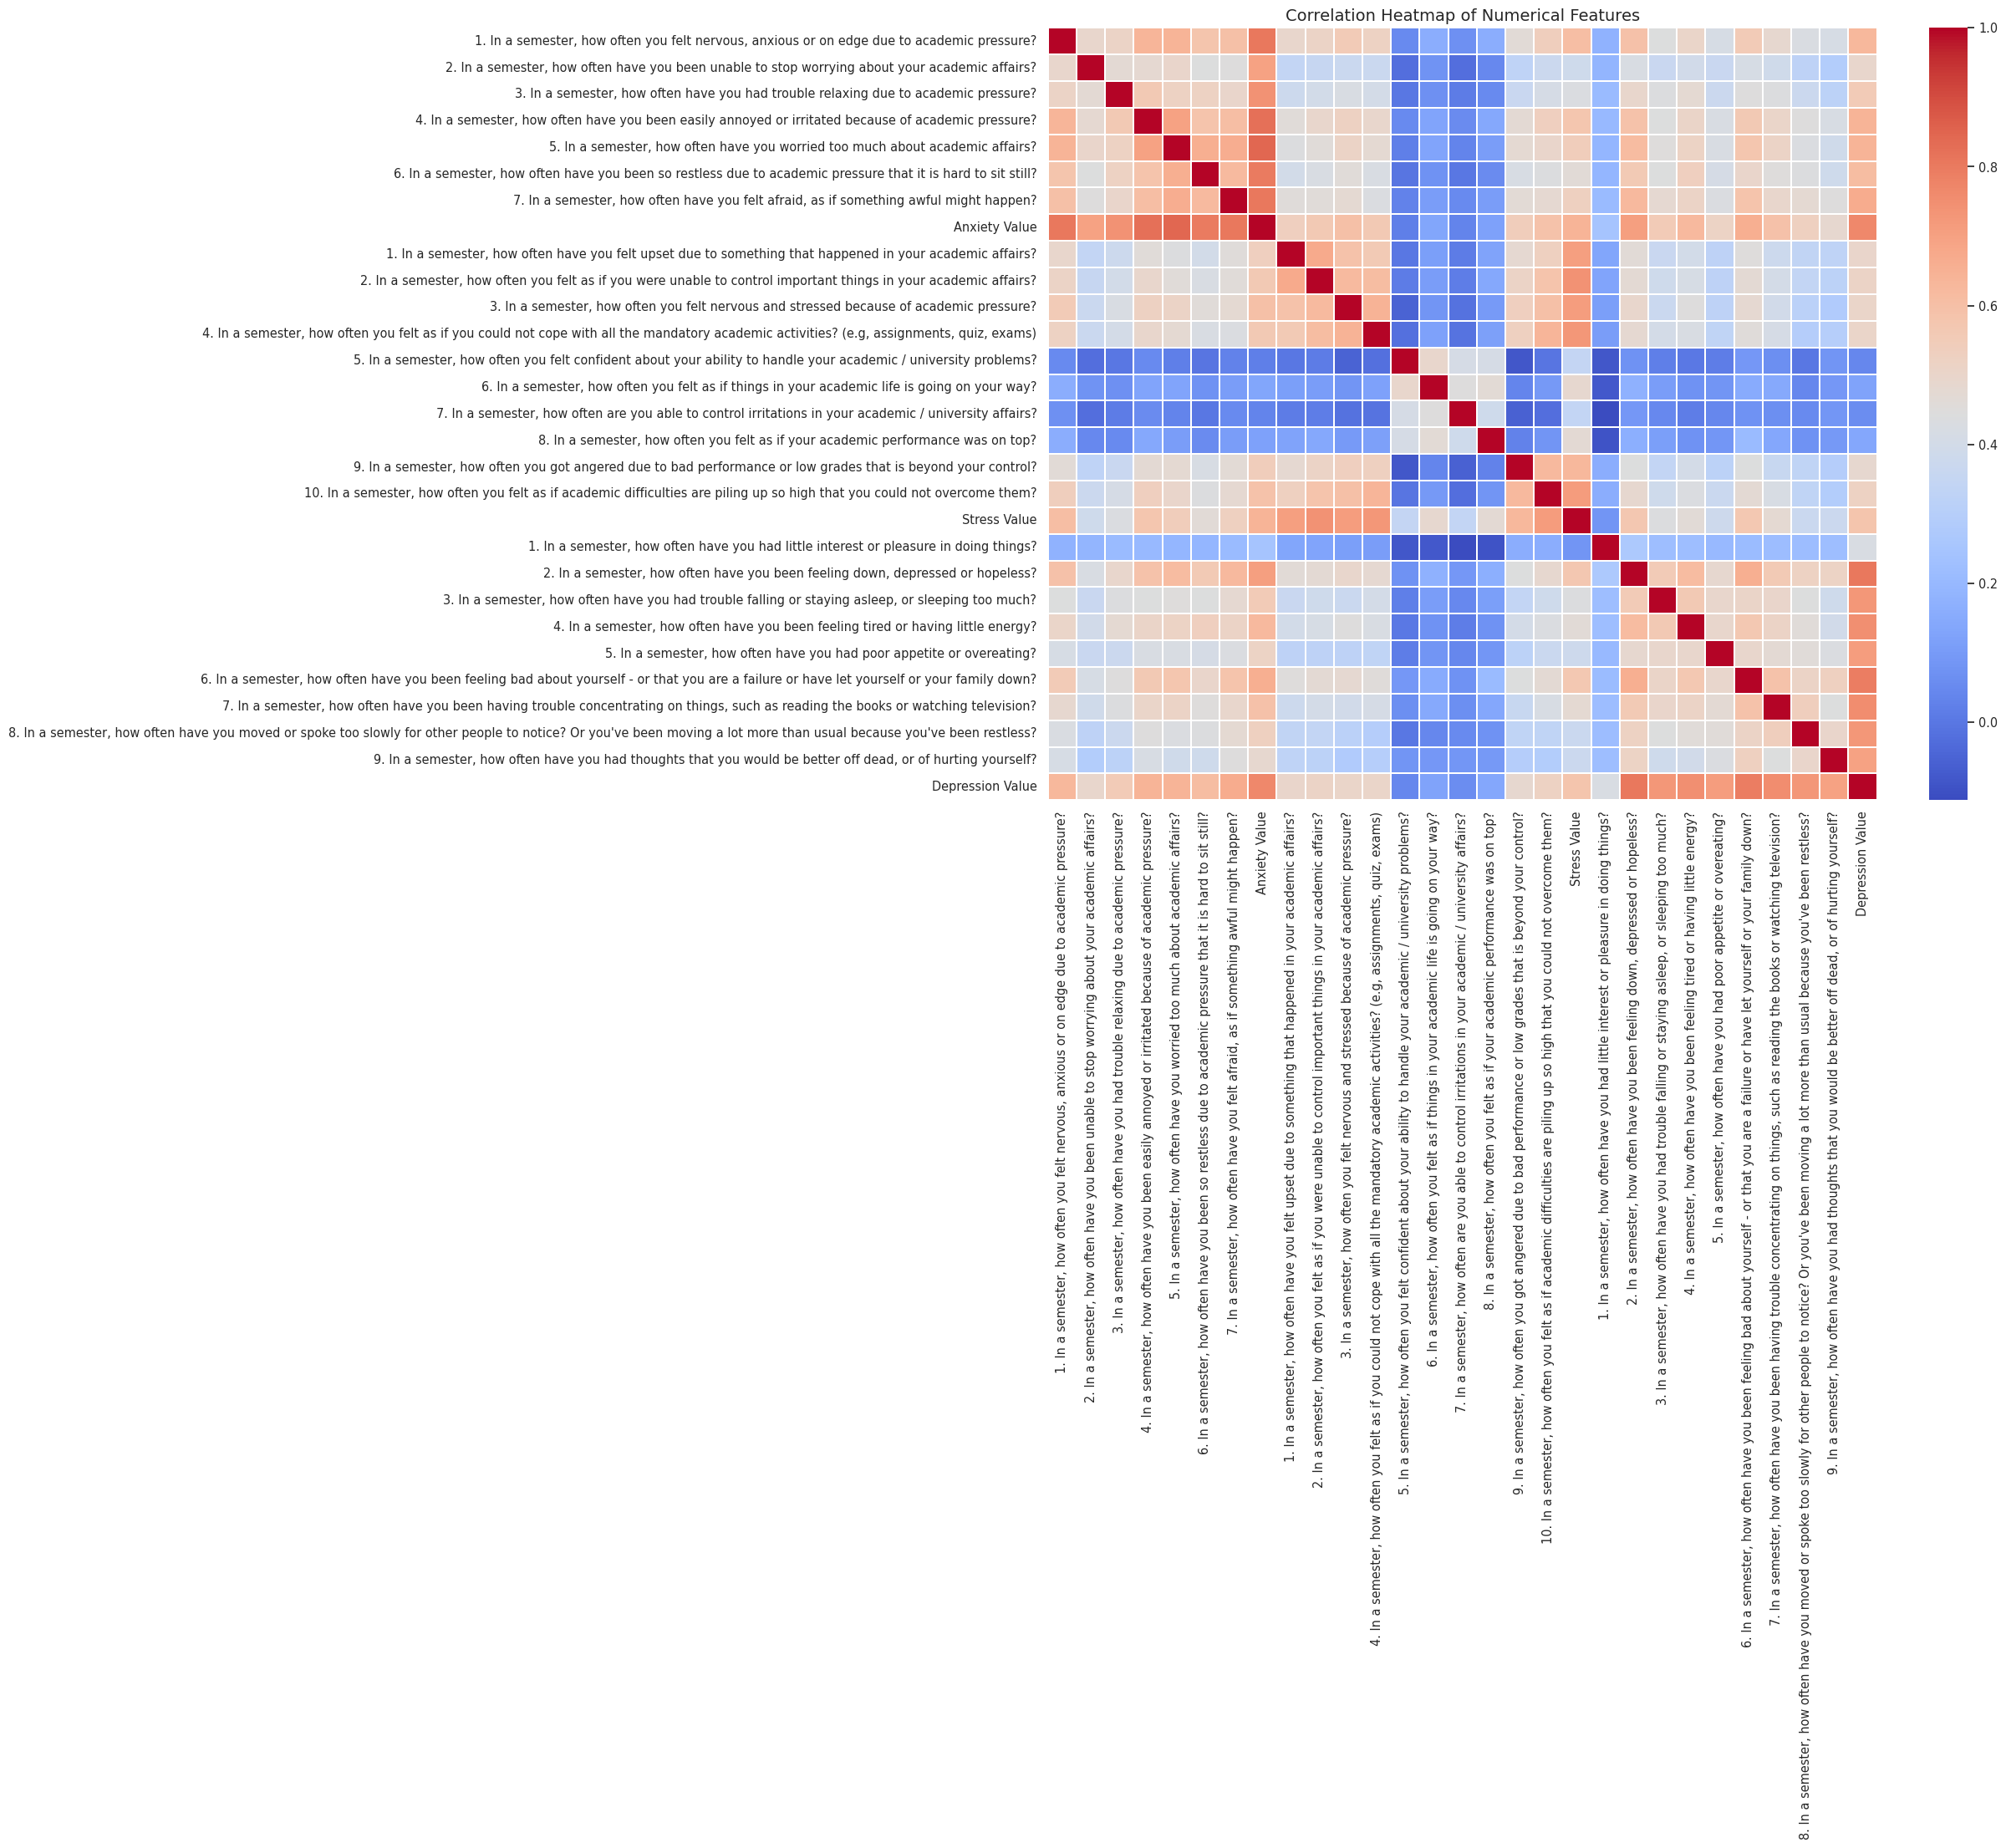

In [3]:
numeric_df = df.select_dtypes(include=['int64','float64'])
if not numeric_df.empty:
    corr = numeric_df.corr(numeric_only=True)
    plt.figure(figsize=(16,12))
    sns.heatmap(corr, annot=False, cmap="coolwarm", linewidths=0.3, square=False)
    plt.title("Correlation Heatmap of Numerical Features", fontsize=14)
    plt.show()
else:
    print("No numeric-only columns found for correlation heatmap.")


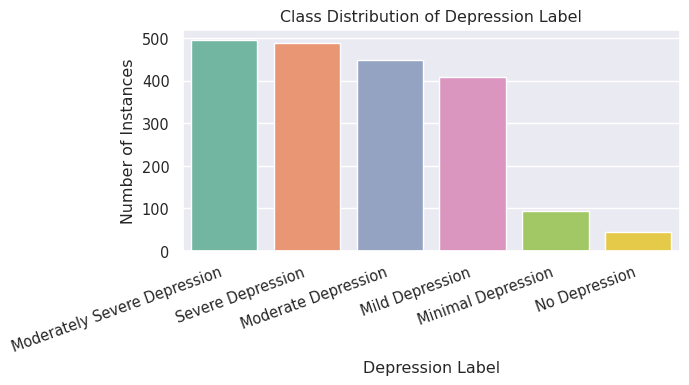

Target distribution:
 Depression Label
Moderately Severe Depression    495
Severe Depression               488
Moderate Depression             449
Mild Depression                 408
Minimal Depression               93
No Depression                    44
Name: count, dtype: int64


In [4]:

# Class Distribution of Target (Depression Label)

if "Depression Label" in df.columns:
    plt.figure(figsize=(7,4))
    counts = df["Depression Label"].value_counts()
    sns.barplot(x=counts.index, y=counts.values, order=counts.index, palette="Set2")
    plt.title("Class Distribution of Depression Label")
    plt.ylabel("Number of Instances")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()
    print("Target distribution:\n", counts)
else:
    print("Depression Label column not found!")


## 4. Data Preprocessing

In [5]:
def map_age(s):
    m = {'Below 18':17.0, '18-22':20.0, '23-26':24.5, '27-30':28.5, 'Above 30':32.0}
    return m.get(s, np.nan)

def map_year(s):
    m = {'First Year or Equivalent':1, 'Second Year or Equivalent':2,
         'Third Year or Equivalent':3, 'Fourth Year or Equivalent':4, 'Other':0}
    return m.get(s, 0)

def map_cgpa(s):
    m = {'Below 2.50':2.25, '2.50 - 2.99':(2.50+2.99)/2, '3.00 - 3.39':(3.00+3.39)/2,
         '3.40 - 3.79':(3.40+3.79)/2, '3.80 - 4.00':(3.80+4.00)/2, 'Other':np.nan}
    return m.get(s, np.nan)

def map_yesno(s):
    if pd.isna(s): return np.nan
    s = str(s).strip().lower()
    if s in ['yes','y','1']: return 1
    if s in ['no','n','0']: return 0
    return np.nan

def map_gender(s):
    return {'Male':1, 'Female':0, 'Prefer not to say':2}.get(s, np.nan)

def map_severity_label(s):
    if pd.isna(s): return np.nan
    s = str(s).strip().lower()
    order = {'normal':0, 'low stress':0, 'minimal anxiety':0,
             'mild':1, 'mild anxiety':1, 'mild stress':1,
             'moderate':2, 'moderate anxiety':2, 'moderate stress':2,
             'high perceived stress':3, 'severe':3, 'severe anxiety':3}
    return order.get(s, np.nan)

if '1. Age' in df: df['1. Age'] = df['1. Age'].map(map_age)
if '2. Gender' in df: df['2. Gender'] = df['2. Gender'].map(map_gender)
if '5. Academic Year' in df: df['5. Academic Year'] = df['5. Academic Year'].map(map_year)
if '6. Current CGPA' in df: df['6. Current CGPA'] = df['6. Current CGPA'].map(map_cgpa)
if '7. Did you receive a waiver or scholarship at your university?' in df:
    df['7. Did you receive a waiver or scholarship at your university?'] = (
        df['7. Did you receive a waiver or scholarship at your university?'].map(map_yesno)
    )
if 'Anxiety Label' in df: df['Anxiety Label'] = df['Anxiety Label'].map(map_severity_label)
if 'Stress Label' in df: df['Stress Label'] = df['Stress Label'].map(map_severity_label)


## 5. Feature Engineering & Scaling

In [6]:
TARGET = 'Depression Label'
assert TARGET in df.columns, f'Expected target column "{TARGET}" not found.'

y_text = df[TARGET].astype(str)
le = LabelEncoder()
y = le.fit_transform(y_text)

drop_cols = [TARGET]
if not USE_DEPRESSION_VALUE_AS_FEATURE and 'Depression Value' in df.columns:
    drop_cols.append('Depression Value')

X = df.drop(columns=drop_cols)

# One-hot any leftover object columns
num_cols = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
obj_cols = [c for c in X.columns if c not in num_cols]
if obj_cols:
    X = pd.get_dummies(X, columns=obj_cols, drop_first=True)

# Impute & scale
imputer = SimpleImputer(strategy='median')
X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_imputed), columns=X_imputed.columns)

print("After preprocessing -> X:", X_scaled.shape, " y:", y.shape)


After preprocessing -> X: (1977, 35)  y: (1977,)


## 6. Train–Test Split

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)

classes = np.unique(y)             # for ROC binarization
y_test_bin = label_binarize(y_test, classes=classes)


## 7. Define Models

In [8]:
models = {
    'KNN': KNeighborsClassifier(n_neighbors=7),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Logistic Regression': LogisticRegression(max_iter=1500),
    'Neural Network': MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation='relu',
        max_iter=1000,
        early_stopping=True,
        n_iter_no_change=10,
        random_state=RANDOM_STATE
    )
}


## 8. Model Training & Evaluation

KNN | Holdout acc: 0.6751 | 5-fold CV: 0.6626 ± 0.0216
              precision    recall  f1-score   support

           0     0.5485    0.9262    0.6890       122
           1     0.7273    0.2857    0.4103        28
           2     0.6552    0.2815    0.3938       135
           3     0.6744    0.7785    0.7227       149
           4     0.6667    0.6154    0.6400        13
           5     0.8741    0.8027    0.8369       147

    accuracy                         0.6751       594
   macro avg     0.6910    0.6150    0.6154       594
weighted avg     0.6959    0.6751    0.6528       594

Decision Tree | Holdout acc: 0.6936 | 5-fold CV: 0.7077 ± 0.0350
              precision    recall  f1-score   support

           0     0.7478    0.7049    0.7257       122
           1     0.5152    0.6071    0.5574        28
           2     0.5857    0.6074    0.5964       135
           3     0.6233    0.6107    0.6169       149
           4     1.0000    1.0000    1.0000        13
           5

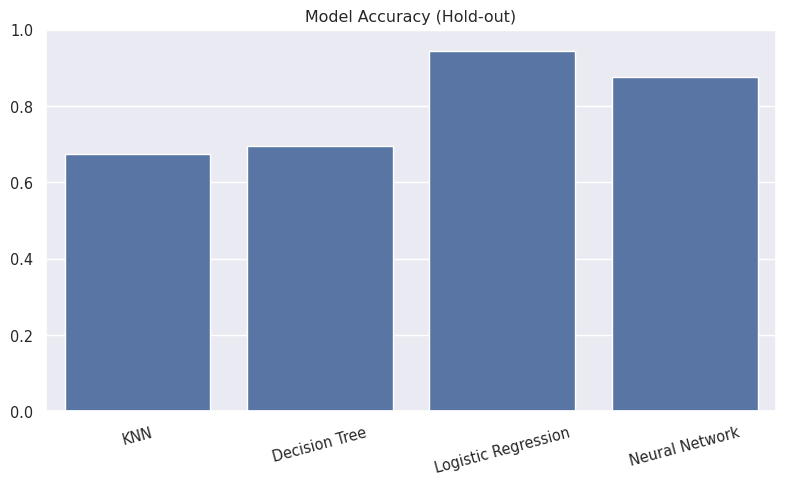

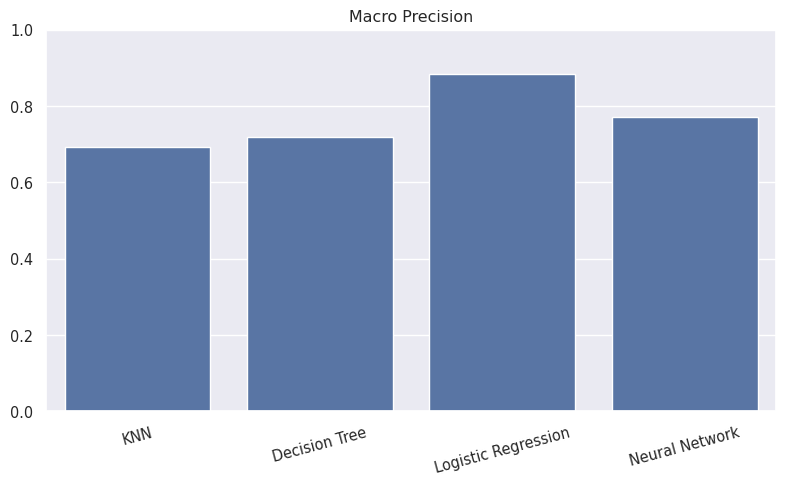

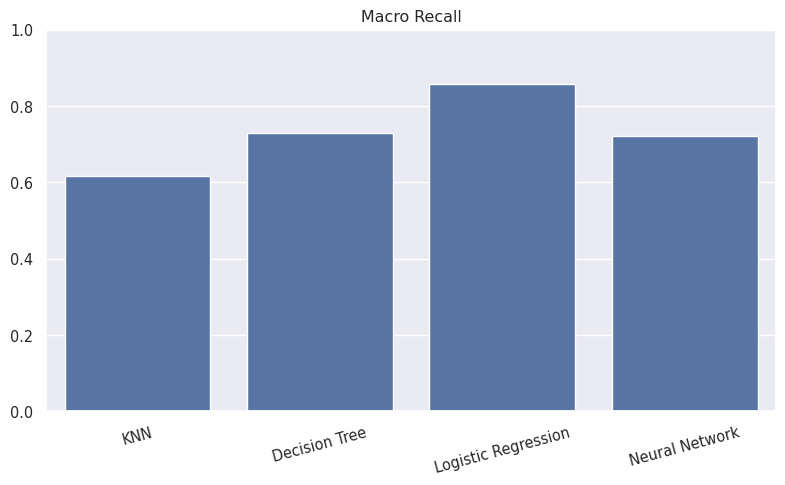

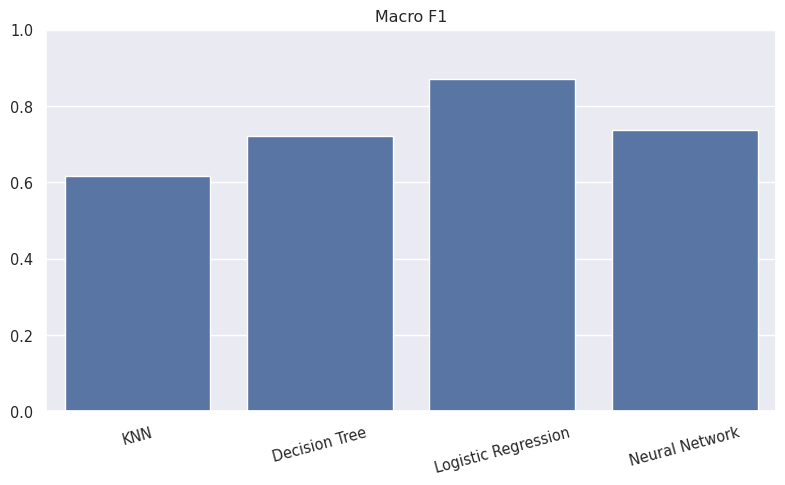

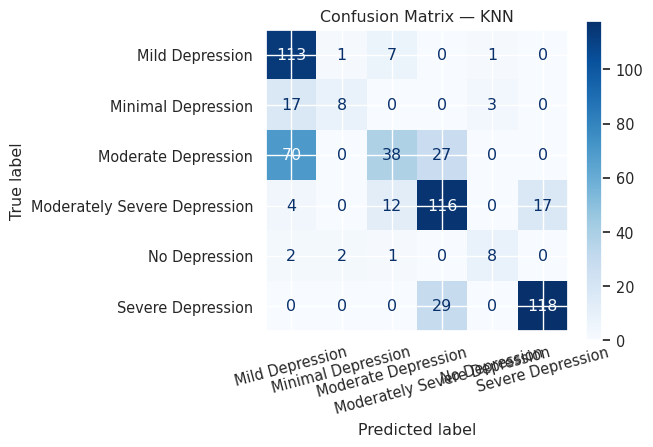

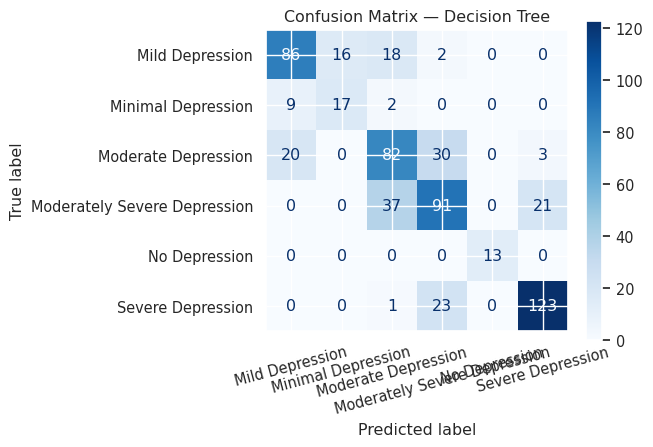

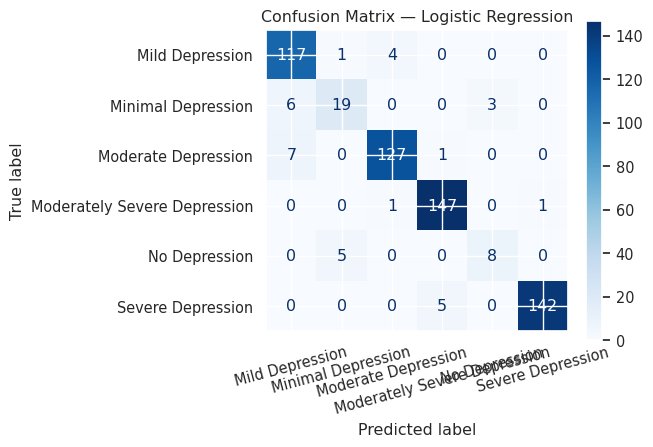

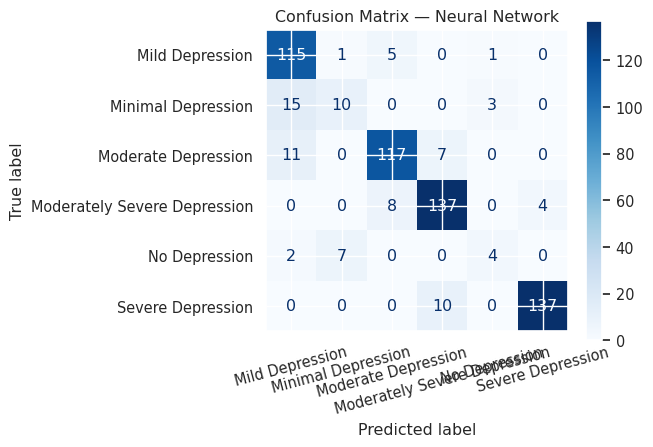

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    rep = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)
    cv_scores = cross_val_score(model, X_scaled, y, cv=cv, scoring='accuracy')

    results[name] = {
        "model": model,
        "y_pred": y_pred,
        "accuracy": float(acc),
        "report": rep,
        "cm": cm,
        "cv_mean": float(np.mean(cv_scores)),
        "cv_std": float(np.std(cv_scores)),
    }

    print(f"{name} | Holdout acc: {acc:.4f} | 5-fold CV: {np.mean(cv_scores):.4f} ± {np.std(cv_scores):.4f}")
    print(classification_report(y_test, y_pred, digits=4))

def barplot_metric(title, values):
    plt.figure(figsize=(8,5))
    sns.barplot(x=list(values.keys()), y=list(values.values()))
    plt.title(title); plt.ylim(0,1.0); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

barplot_metric("Model Accuracy (Hold-out)", {k:v["accuracy"] for k,v in results.items()})
barplot_metric("Macro Precision", {k:v["report"]["macro avg"]["precision"] for k,v in results.items()})
barplot_metric("Macro Recall", {k:v["report"]["macro avg"]["recall"] for k,v in results.items()})
barplot_metric("Macro F1", {k:v["report"]["macro avg"]["f1-score"] for k,v in results.items()})

# Confusion matrices
for name, res in results.items():
    disp = ConfusionMatrixDisplay(confusion_matrix=res["cm"], display_labels=le.classes_)
    disp.plot(values_format='d', cmap="Blues")
    plt.title(f"Confusion Matrix — {name}")
    plt.xticks(rotation=15); plt.tight_layout(); plt.show()


## 9. ROC Curves

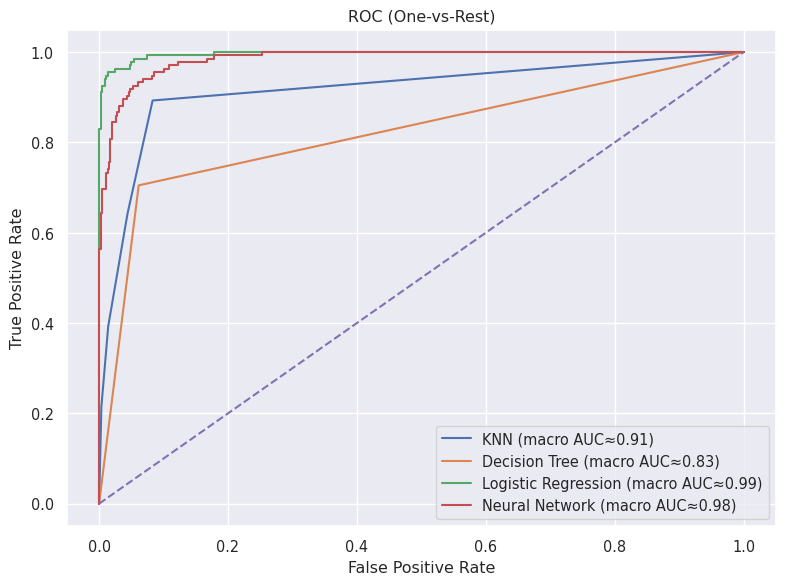

In [10]:
# ---- Multiclass ROC/AUC (OvR) — plot a representative curve and show macro AUC
classes = np.unique(y)
y_test_bin = label_binarize(y_test, classes=classes)

plt.figure(figsize=(8,6))
for name, res in results.items():
    model = res['model']
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)
    elif hasattr(model, "decision_function"):
        dec = model.decision_function(X_test)
        # convert to pseudo-probabilities for plotting
        exp = np.exp(dec - np.max(dec, axis=1, keepdims=True))
        y_score = exp / exp.sum(axis=1, keepdims=True)
    else:
        # worst-case fallback (not ideal, but keeps code runnable)
        y_score = label_binarize(res['y_pred'], classes=classes)

    aucs, curves = [], []
    for i in range(len(classes)):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        curves.append((fpr, tpr))
        aucs.append(auc(fpr, tpr))

    # Plot the curve for the median AUC
    mid = int(np.argsort(aucs)[len(aucs)//2])
    fpr, tpr = curves[mid]
    plt.plot(fpr, tpr, label=f"{name} (macro AUC≈{np.mean(aucs):.2f})")

plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC (One-vs-Rest)")
plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()


## 10. Unsupervised Learning (K-Means Clustering)

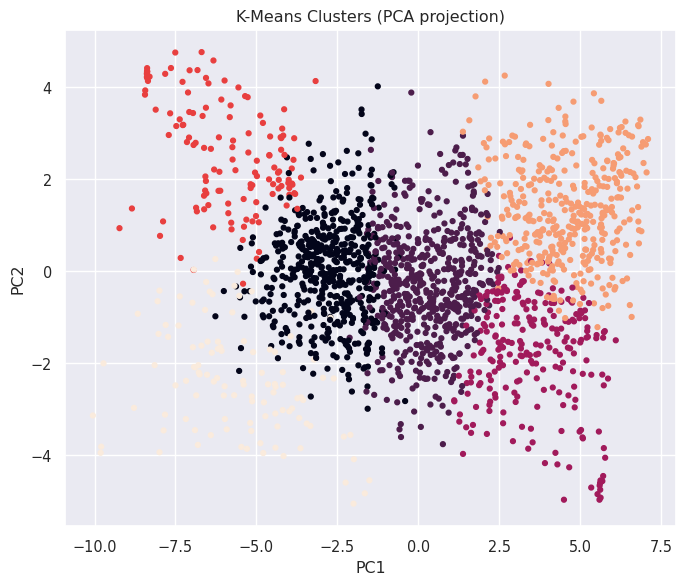

In [13]:
k = len(le.classes_)  # clusters = number of label categories
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X2 = pca.fit_transform(X_scaled)

kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
km_labels = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(7,6))
plt.scatter(X2[:,0], X2[:,1], c=km_labels, s=12)
plt.title("K-Means Clusters (PCA projection)")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.tight_layout(); plt.show()


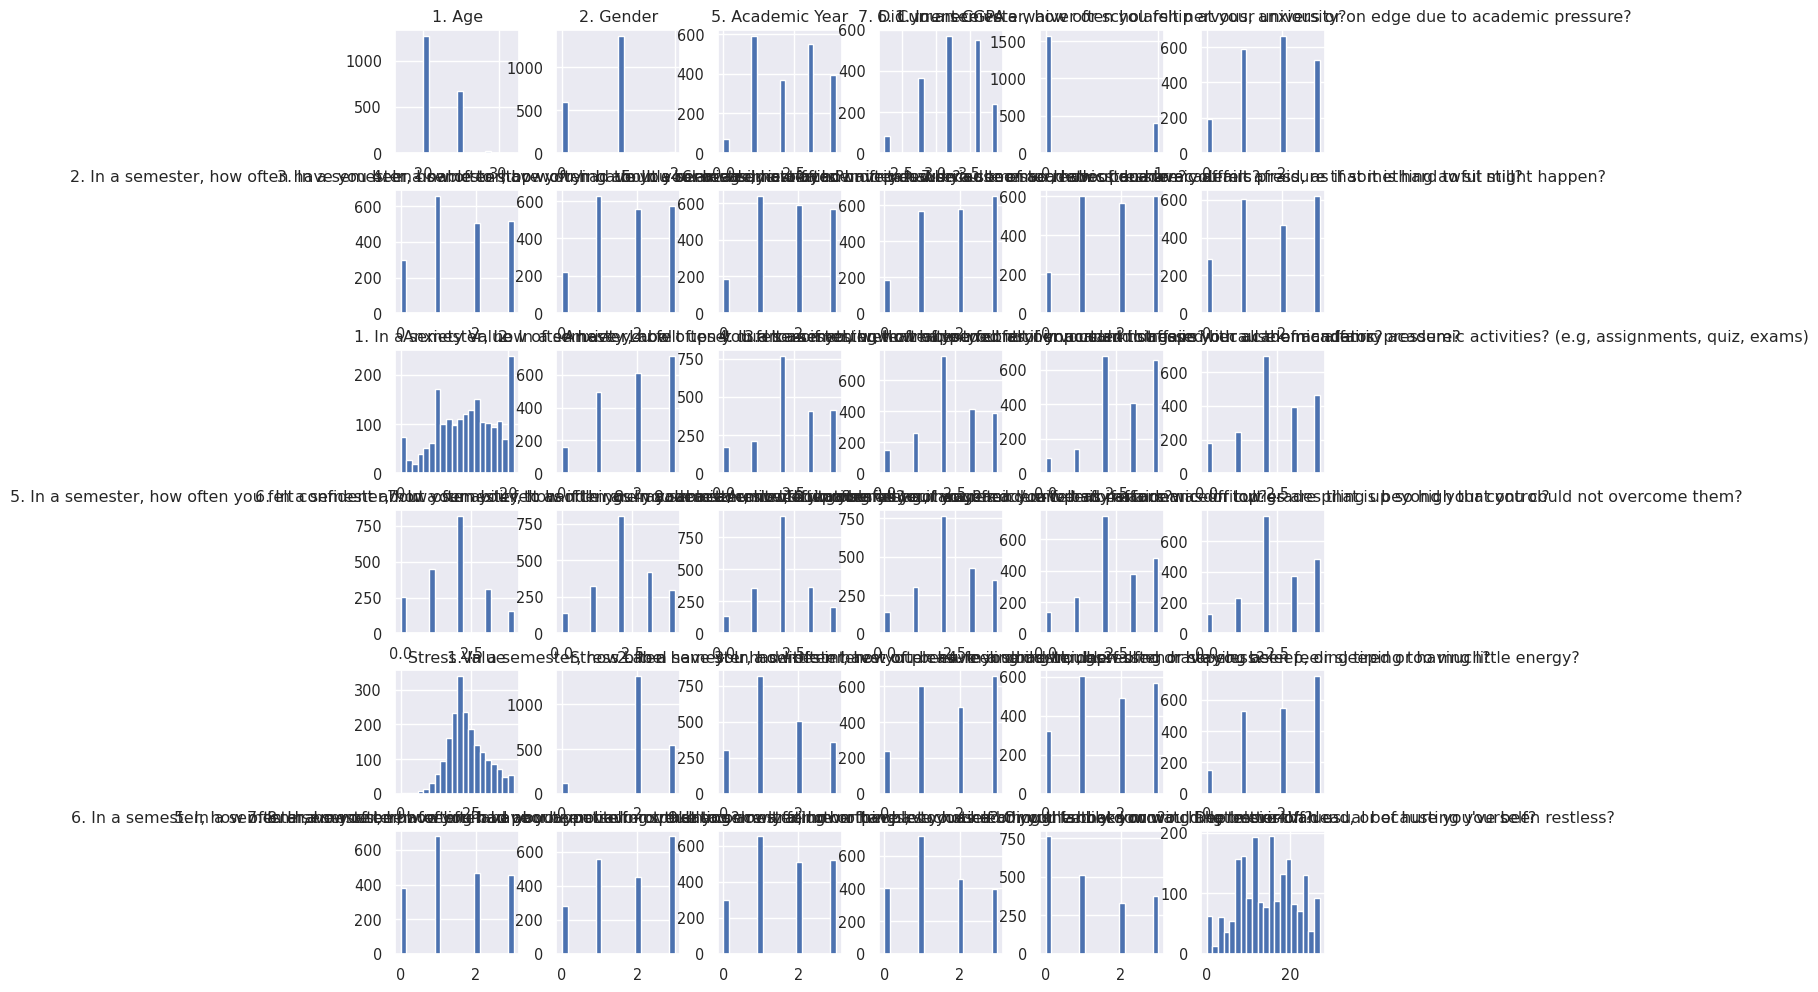

In [16]:
import matplotlib.pyplot as plt

# If your full dataset is in a DataFrame called df
numerical_data = df.select_dtypes(include=['int64', 'float64'])

# Now plot histograms
numerical_data.hist(figsize=(12, 12), bins=20)
plt.show()